In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load both datasets
fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

In [3]:
# Assign labels
fake["label"] = 1
true["label"] = 0

In [4]:
# Combine both datasets
data = pd.concat([fake, true], ignore_index=True)

In [5]:
data.shape

(44898, 5)

In [6]:
data.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1


In [7]:
data.isnull().sum()

title      0
text       0
subject    0
date       0
label      0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(209)

In [9]:
data.drop_duplicates(inplace=True)

In [10]:
data.shape

(44689, 5)

In [11]:
# Keep the columns required for prediction
data = data[["title", "text", "label"]]

In [12]:
# Remove missing and duplicate records
data = data.dropna(subset=["title", "text"])
data = data.drop_duplicates(subset=["title", "text"])

In [13]:
# this is my model input 
# Combine headline and article text
data["content"] = (
    data["title"].astype(str) + " " +
    data["text"].astype(str)
)

In [14]:
print(data.head())
print("\nDataset shape:", data.shape)
print("\nClass distribution:")
print(data["label"].value_counts())

                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text  label  \
0  Donald Trump just couldn t wish all Americans ...      1   
1  House Intelligence Committee Chairman Devin Nu...      1   
2  On Friday, it was revealed that former Milwauk...      1   
3  On Christmas day, Donald Trump announced that ...      1   
4  Pope Francis used his annual Christmas Day mes...      1   

                                             content  
0   Donald Trump Sends Out Embarrassing New Year’...  
1   Drunk Bragging Trump Staffer Started Russian ...  
2   Sheriff David Clarke Becomes An Internet Joke...  
3   Trump Is So Obsessed He Even Has Obama’s Name...  
4   Pope 

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
import joblib

In [16]:
# Input and target
X = data["content"]
y = data["label"]

In [17]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [18]:
# Create the complete ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_df=0.7,
        max_features=50000,
        ngram_range=(1, 2)
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample",
        max_features="sqrt"
    ))
])

In [19]:
data.columns

Index(['title', 'text', 'label', 'content'], dtype='str')

In [20]:
# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [21]:
# Evaluate the model

In [22]:
# Make predictions
y_pred = model.predict(X_test)

In [23]:
model.score(X_train, y_train)

1.0

In [24]:
model.score(X_test,y_test)

0.9914333205472446

In [25]:
# Use the test accuracy reported in the evaluation cells below.
accuracy_score(y_test, y_pred)

0.9914333205472446

In [26]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 99.14 %


In [27]:
# Evaluation Metrics it is used to check how well our model is performing
# Precision, recall, F1-score
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Real News", "Fake News"]
))


Classification Report:
              precision    recall  f1-score   support

   Real News       0.99      1.00      0.99      4239
   Fake News       1.00      0.99      0.99      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



In [28]:
import matplotlib.pyplot as plt

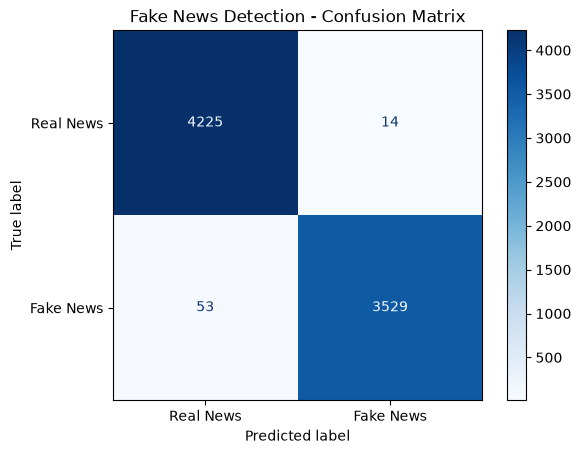

In [29]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real News", "Fake News"]
)

display.plot(cmap="Blues")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()

In [30]:
# Save our trained model

In [31]:
joblib.dump(model, "fake_news_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [32]:
model = joblib.load("fake_news_model.pkl")